<a href="https://colab.research.google.com/github/Anhelina4/email-engagement-by-signup-cohort/blob/main/Email_Engagement_by_Signup_Cohort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
from google.colab import userdata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
source_path = userdata.get('data_source_path')
data = pd.read_csv(source_path)

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38985 entries, 0 to 38984
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   account_id            38985 non-null  int64 
 1   account_created_date  38985 non-null  object
 2   visit_date            19418 non-null  object
dtypes: int64(1), object(2)
memory usage: 913.8+ KB


In [113]:
data['account_created_date'] = pd.to_datetime(data['account_created_date'])
data['visit_date'] = pd.to_datetime(data['visit_date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38985 entries, 0 to 38984
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   account_id            38985 non-null  int64         
 1   account_created_date  38985 non-null  datetime64[ns]
 2   visit_date            19418 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1)
memory usage: 913.8 KB


In [114]:
min_date = data['account_created_date'].min()
max_date = data['account_created_date'].max()
print(max_date - min_date)

87 days 00:00:00


In [115]:
# Cohort      = week the account was created
# Metric      = email visit
# Cohort index = full weeks between the visit week and the cohort week

WEEK = 'W-SUN'   # Monday-start weeks

data['cohort_week'] = data['account_created_date'].dt.to_period(WEEK).dt.start_time
data['visit_week']  = data['visit_date'].dt.to_period(WEEK).dt.start_time

data['cohort_index'] = (data['visit_week'] - data['cohort_week']).dt.days // 7

# cohort size = everyone who registered, not just week-0 email visitors
cohort_sizes = data.groupby('cohort_week')['account_id'].nunique()

active_cohort_subscribers = (
    data.groupby(['cohort_week', 'cohort_index'])['account_id']
        .nunique()
        .unstack(1)
)

retention = active_cohort_subscribers.divide(cohort_sizes, axis=0) * 100
retention.columns = retention.columns.astype(int)

retention.round(2)

cohort_index,0,1,2,3,4,5
cohort_week,,,,,,
2020-10-26,3.12,7.81,4.17,6.25,2.60,NaN
2020-11-02,8.68,8.39,6.24,4.84,3.32,NaN
2020-11-09,7.87,7.32,5.34,4.31,3.08,0.21
2020-11-16,6.82,7.52,5.41,3.53,2.82,0.06
2020-11-23,8.61,8.45,6.20,4.55,2.62,0.05
2020-11-30,7.95,8.25,6.23,4.50,2.67,0.05
2020-12-07,8.24,8.24,5.19,4.66,2.82,0.08
2020-12-14,8.10,7.61,6.09,4.57,2.86,0.09
2020-12-21,7.55,8.02,5.95,4.61,2.81,0.07


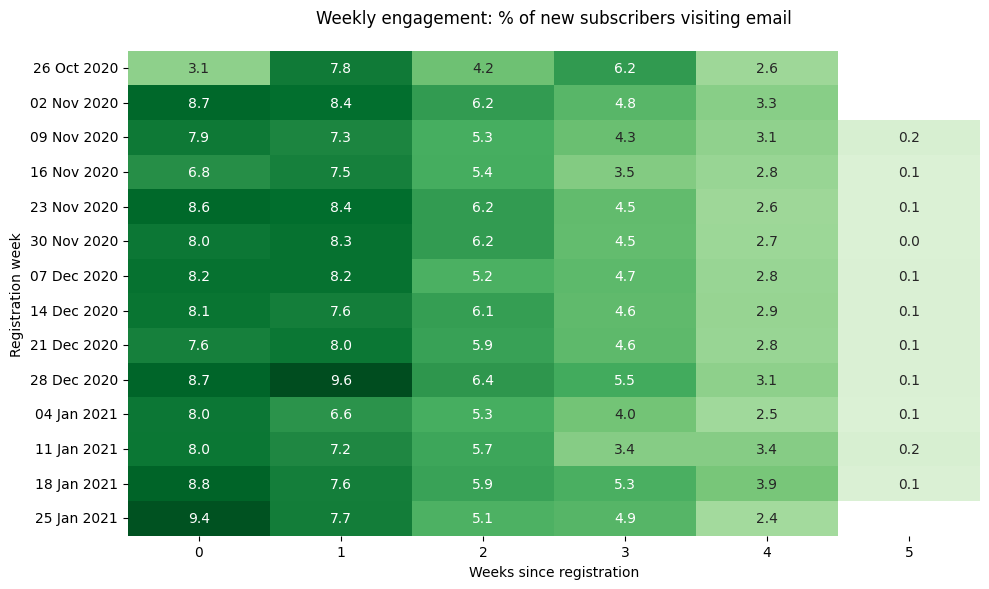

In [116]:
retention.index = retention.index.strftime('%d %b %Y')
plt.figure(figsize=(10, 6))
sns.heatmap(retention, annot=True, fmt='.1f', cbar=False, cmap='Greens', vmin=-2, vmax=10)

plt.title('Weekly engagement: % of new subscribers visiting email', pad=20)
plt.xlabel('Weeks since registration')
plt.ylabel('Registration week')

plt.tight_layout()
plt.show()


In [120]:
cohort_data = active_cohort_subscribers.stack(0).rename('active_users').reset_index()

registrations = cohort_sizes.rename('active_users').reset_index()
registrations['cohort_index'] = -1
registrations['retention_pct'] = 100

merged = pd.concat([cohort_data, registrations], axis=0).sort_values(['cohort_week', 'cohort_index'], ascending=[True, True])
export = merged.merge(cohort_sizes, on='cohort_week', how='left').rename(columns={'account_id': 'registrations'})
export['retention_pct'] = export['active_users'] / export['registrations'] * 100


drive_path = userdata.get('drive_path')
export.to_csv(f'{drive_path}/retention.csv')

,cohort_week,cohort_index,active_users,retention_pct,registrations
0,2020-10-26,-1.0,192.0,100.000000,192
1,2020-10-26,0.0,6.0,3.125000,192
2,2020-10-26,1.0,15.0,7.812500,192
3,2020-10-26,2.0,8.0,4.166667,192
4,2020-10-26,3.0,12.0,6.250000,192
...,...,...,...,...,...
90,2021-01-25,0.0,70.0,9.446694,741
91,2021-01-25,1.0,57.0,7.692308,741
92,2021-01-25,2.0,38.0,5.128205,741
93,2021-01-25,3.0,36.0,4.858300,741
